# 複数シート：まず直接法の像を設計する

1枚用の係数を5枚にコピーすると、シート間の干渉で背景光が強くなることを確認しました。このノートブックは、コピー方式と、全体の目標強度に合わせて**シート別の係数**を反復調整する方式を比較します。

ここでは解析的なBessel重ね合わせだけを計算します。**Tucker圧縮・有限開口・CGH化・4f・センサーへの伝搬計算はまだ行いません。** 新しい係数設計は論文の非反復設計そのものではなく、追加の検証です。きれいになるかは結果で確認してください。

出力画像の強度は共通のスケールです。結果を見るための正規化で、画質や光量の誤差を消す処理はありません。


In [1]:
import importlib
from datetime import datetime
from pathlib import Path
from IPython.display import Image, display
import lsh_multisheet as multisheet
import lsh_multisheet_design as design3d
multisheet = importlib.reload(multisheet)
design3d = importlib.reload(design3d)

REFERENCE_DIR = Path('lsh_digits123_rank_verified_outputs_rank512_parent512_v1')
OUTPUT_DIR = Path(f'lsh_multisheet_design_outputs_{datetime.now():%Y%m%d_%H%M%S_%f}')
stack = multisheet.MultiSheetConfig(
    rank=450, parent_rank=512, sheet_count=5, sheet_spacing_m=75e-6,
    z_samples=101, evaluation_y_half_width_m=500e-6, padding_factor=2,
    timing_repeats=1, timing_warmups=0,
)
settings = design3d.JointDesignConfig(
    fit_x_samples=145, fit_y_samples=81, fit_z_samples=128,
    iterations=30, ridge_relative=1e-4, max_design_memory_mib=2048,
)
print('保存先:', OUTPUT_DIR.resolve())
print('y中心座標[um]:', stack.y_positions() * 1e6)
print('krは元の43モードを使用。今回は量・範囲・ランクを同時に変更しません。')


保存先: C:\Users\kota-\Github\Project_new\research\lsh_multisheet_design_outputs_20261005_175214_035547
y中心座標[um]: [-150.  -75.    0.   75.  150.]
krは元の43モードを使用。今回は量・範囲・ランクを同時に変更しません。


## 何を調整するか

光場は $E=\sum_{m,s,q} a_{msq}J_0(k_{r,m}r_{sq})e^{ik_{z,m}z}$ です。目標の強度に対応する振幅を指定し、その位相とBessel係数を交互に更新します。目標の外側は振幅0とし、背景光も目的関数に含めます。

係数は $[m,s,q]$（モード・シート・Thread）の配列になります。同じ「123」を重ねる目標でも、干渉を抑えるため、各シートの係数は異なります。直接法と提案法の比較時は、この同じ係数を両方に渡します。

設計用の格子と、評価用の7 µm格子・101深度は分けます。目的関数が設計格子で下がっても、評価格子や有限CGHで改善する保証はありません。反復計算は準備時間として記録し、オンライン生成時間には含めません。


In [2]:
summary = design3d.run_joint_design(REFERENCE_DIR, OUTPUT_DIR, stack, settings)
print('結果:', (OUTPUT_DIR / 'design_summary.json').resolve())
print('後段に渡す係数:', (OUTPUT_DIR / 'coefficient_design.npz').resolve())


3D transverse fit: mode 1/43
3D transverse fit: mode 2/43
3D transverse fit: mode 3/43
3D transverse fit: mode 4/43
3D transverse fit: mode 5/43
3D transverse fit: mode 6/43
3D transverse fit: mode 7/43
3D transverse fit: mode 8/43
3D transverse fit: mode 9/43
3D transverse fit: mode 10/43
3D transverse fit: mode 11/43
3D transverse fit: mode 12/43
3D transverse fit: mode 13/43
3D transverse fit: mode 14/43
3D transverse fit: mode 15/43
3D transverse fit: mode 16/43
3D transverse fit: mode 17/43
3D transverse fit: mode 18/43
3D transverse fit: mode 19/43
3D transverse fit: mode 20/43
3D transverse fit: mode 21/43
3D transverse fit: mode 22/43
3D transverse fit: mode 23/43
3D transverse fit: mode 24/43
3D transverse fit: mode 25/43
3D transverse fit: mode 26/43
3D transverse fit: mode 27/43
3D transverse fit: mode 28/43
3D transverse fit: mode 29/43
3D transverse fit: mode 30/43
3D transverse fit: mode 31/43
3D transverse fit: mode 32/43
3D transverse fit: mode 33/43
3D transverse fit: 

In [3]:
print('解析的な直接法だけの評価（CGH replayではありません）')
print('方式 | 目標強度の相対L2誤差[%] | 目標外の光量[%] | 厚み外の光量[%] | 明部の強度CV')
for name, label in [('copied', '1枚用係数のコピー'), ('joint', '全体で係数を調整')]:
    score = summary['evaluation'][name]
    print(f"{label} | {100*score['intensity_relative_l2']:.3f} | "
          f"{100*score['off_target_power_fraction_in_roi']:.3f} | "
          f"{100*score['thickness']['out_of_slab_power_fraction_in_saved_roi']:.3f} | "
          f"{score['on_target_intensity_cv']:.4f}")
print('別格子での強度L2誤差が改善:', summary['evaluation_improved_intensity_l2'])
print('強度コサイン類似度（光量差に依存しない）:', {name: score['intensity_cosine_similarity_to_target'] for name, score in summary['evaluation'].items()})
print('形状類似度が改善:', summary['evaluation_improved_shape_cosine'])
print('係数設計の準備時間[秒]:', summary['coefficient_design_seconds'])
print('各y断面のSSIM/PSNR等:', OUTPUT_DIR / 'design_summary.json')
print('反復履歴:', OUTPUT_DIR / 'iterations.csv')


解析的な直接法だけの評価（CGH replayではありません）
方式 | 目標強度の相対L2誤差[%] | 目標外の光量[%] | 厚み外の光量[%] | 明部の強度CV
1枚用係数のコピー | 964.848 | 73.757 | 63.311 | 0.9512
全体で係数を調整 | 93.156 | 68.559 | 60.288 | 0.9865
別格子での強度L2誤差が改善: True
強度コサイン類似度（光量差に依存しない）: {'copied': 0.46215283812999397, 'joint': 0.4768330882987087}
形状類似度が改善: True
係数設計の準備時間[秒]: 18.581041899999946
各y断面のSSIM/PSNR等: lsh_multisheet_design_outputs_20261005_175214_035547\design_summary.json
反復履歴: lsh_multisheet_design_outputs_20261005_175214_035547\iterations.csv


analytic_sheets.png


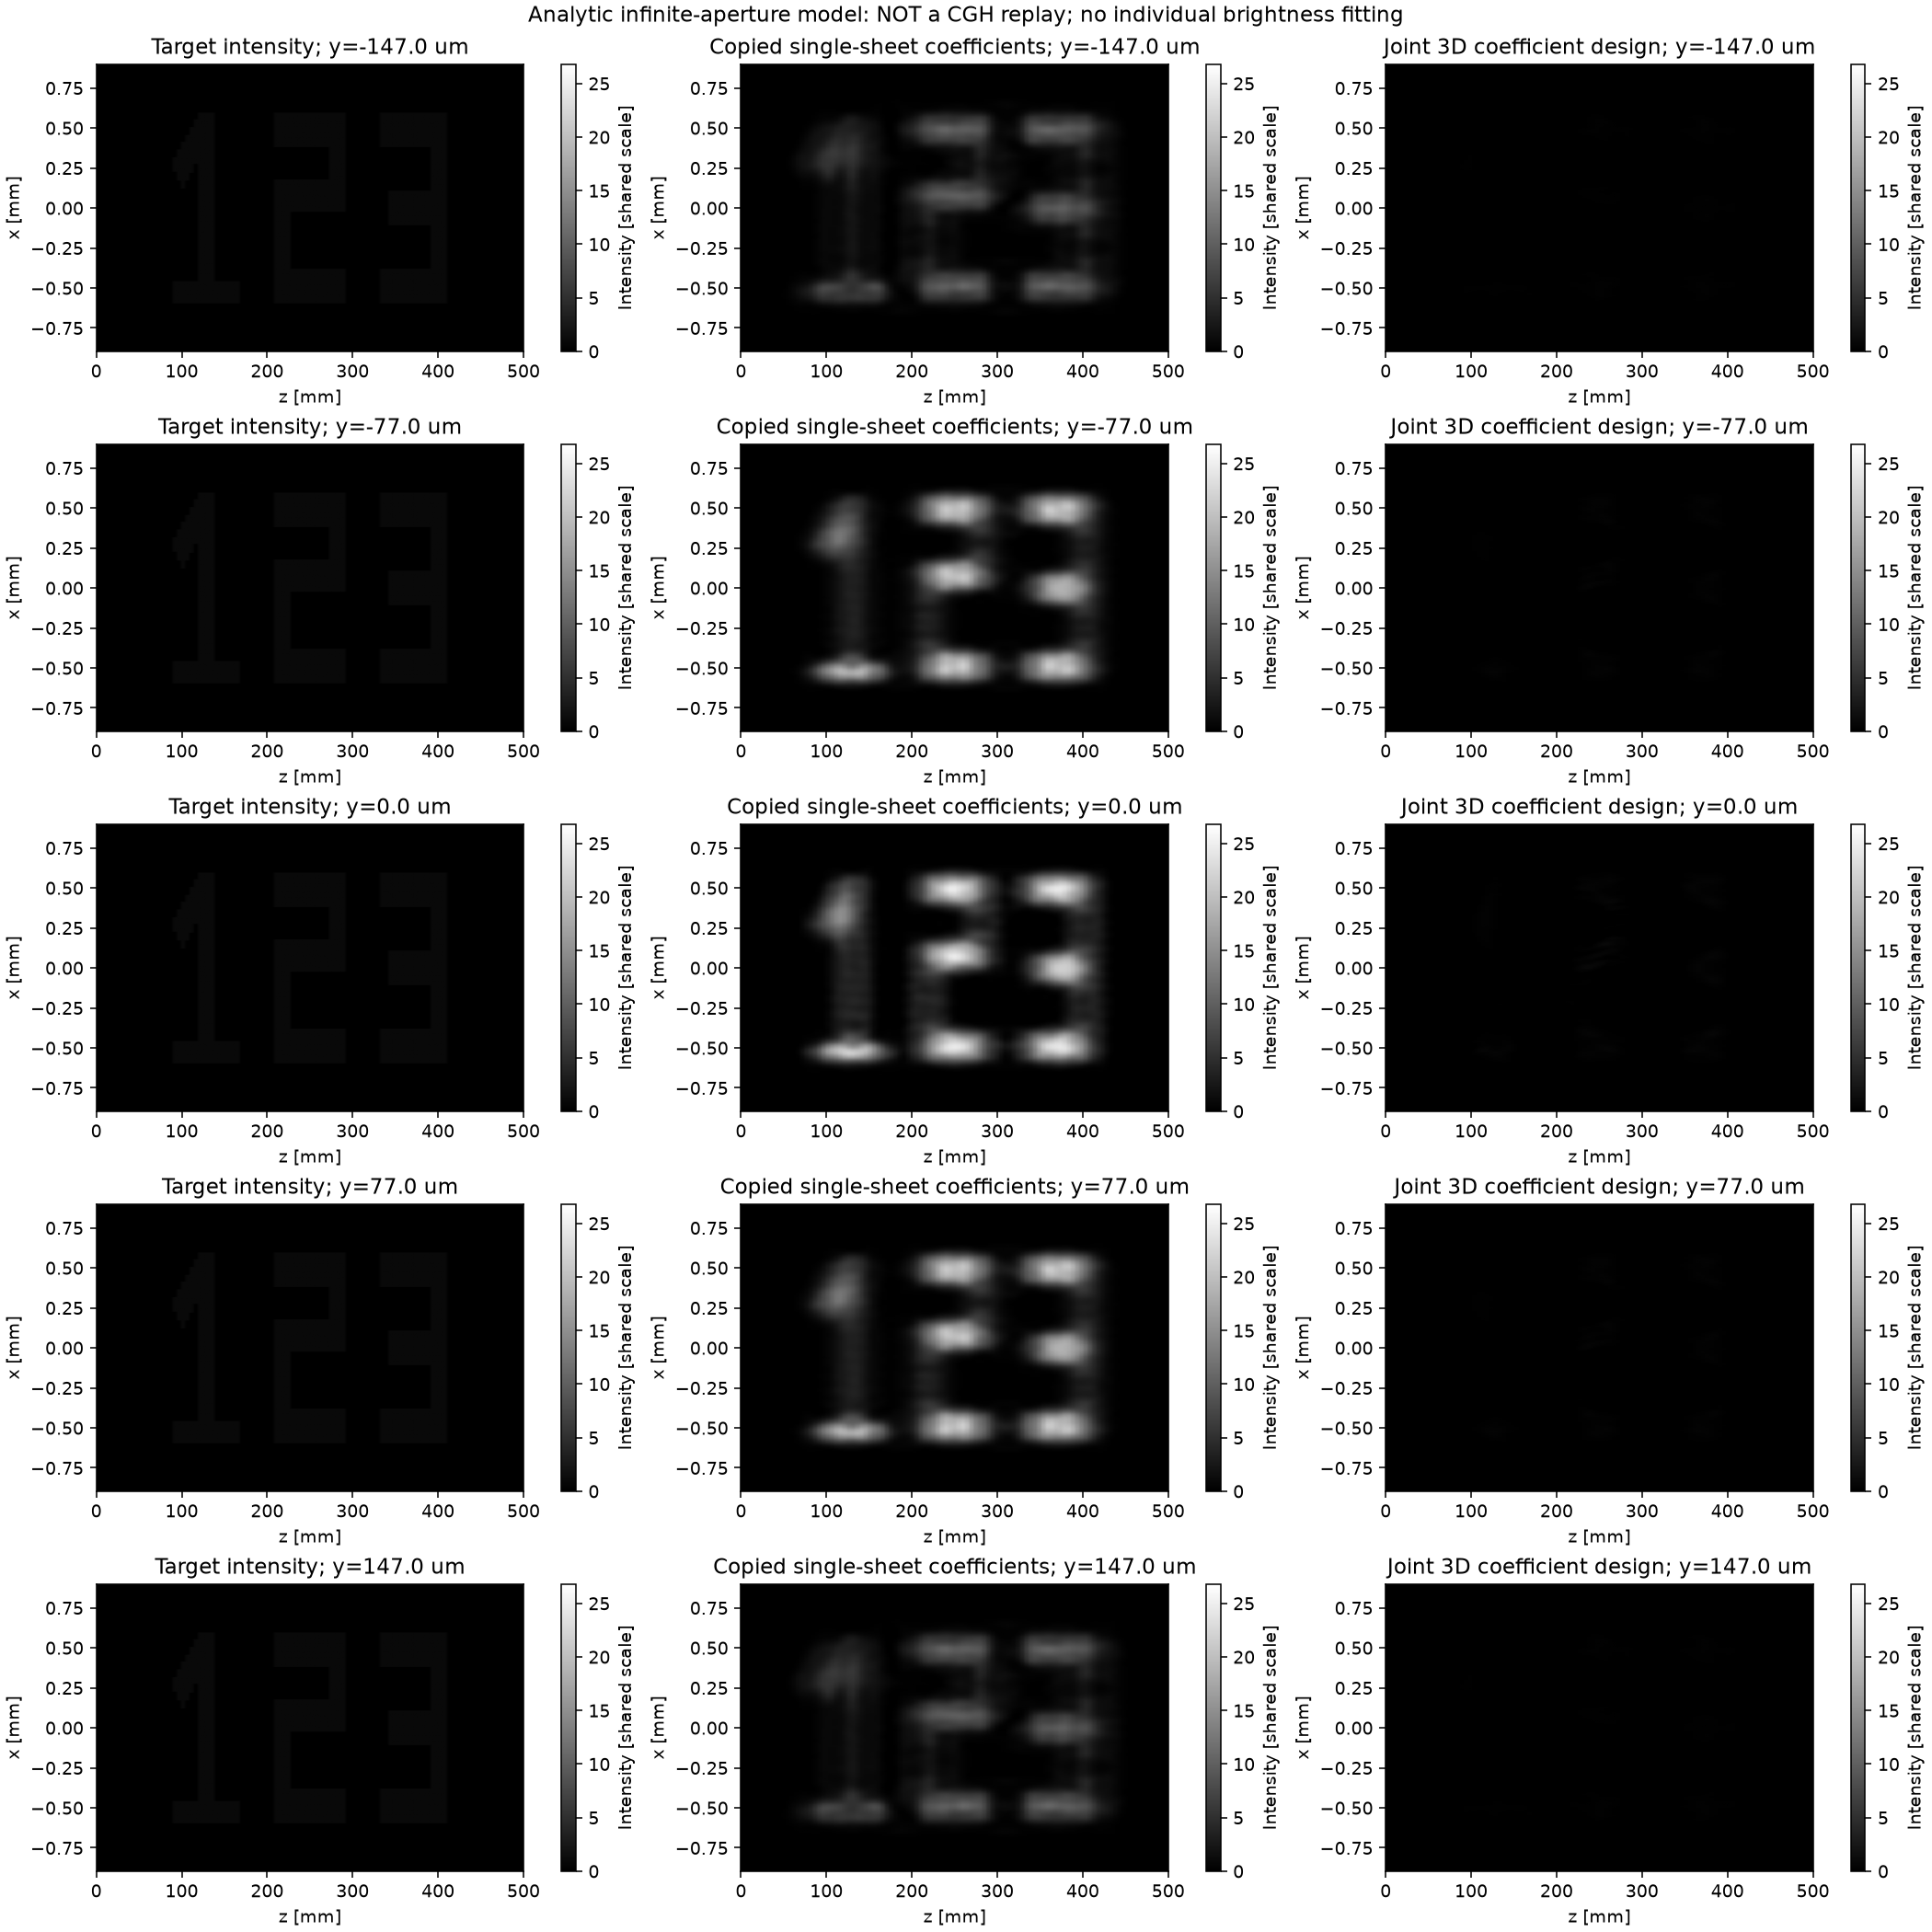

analytic_sheets_db.png


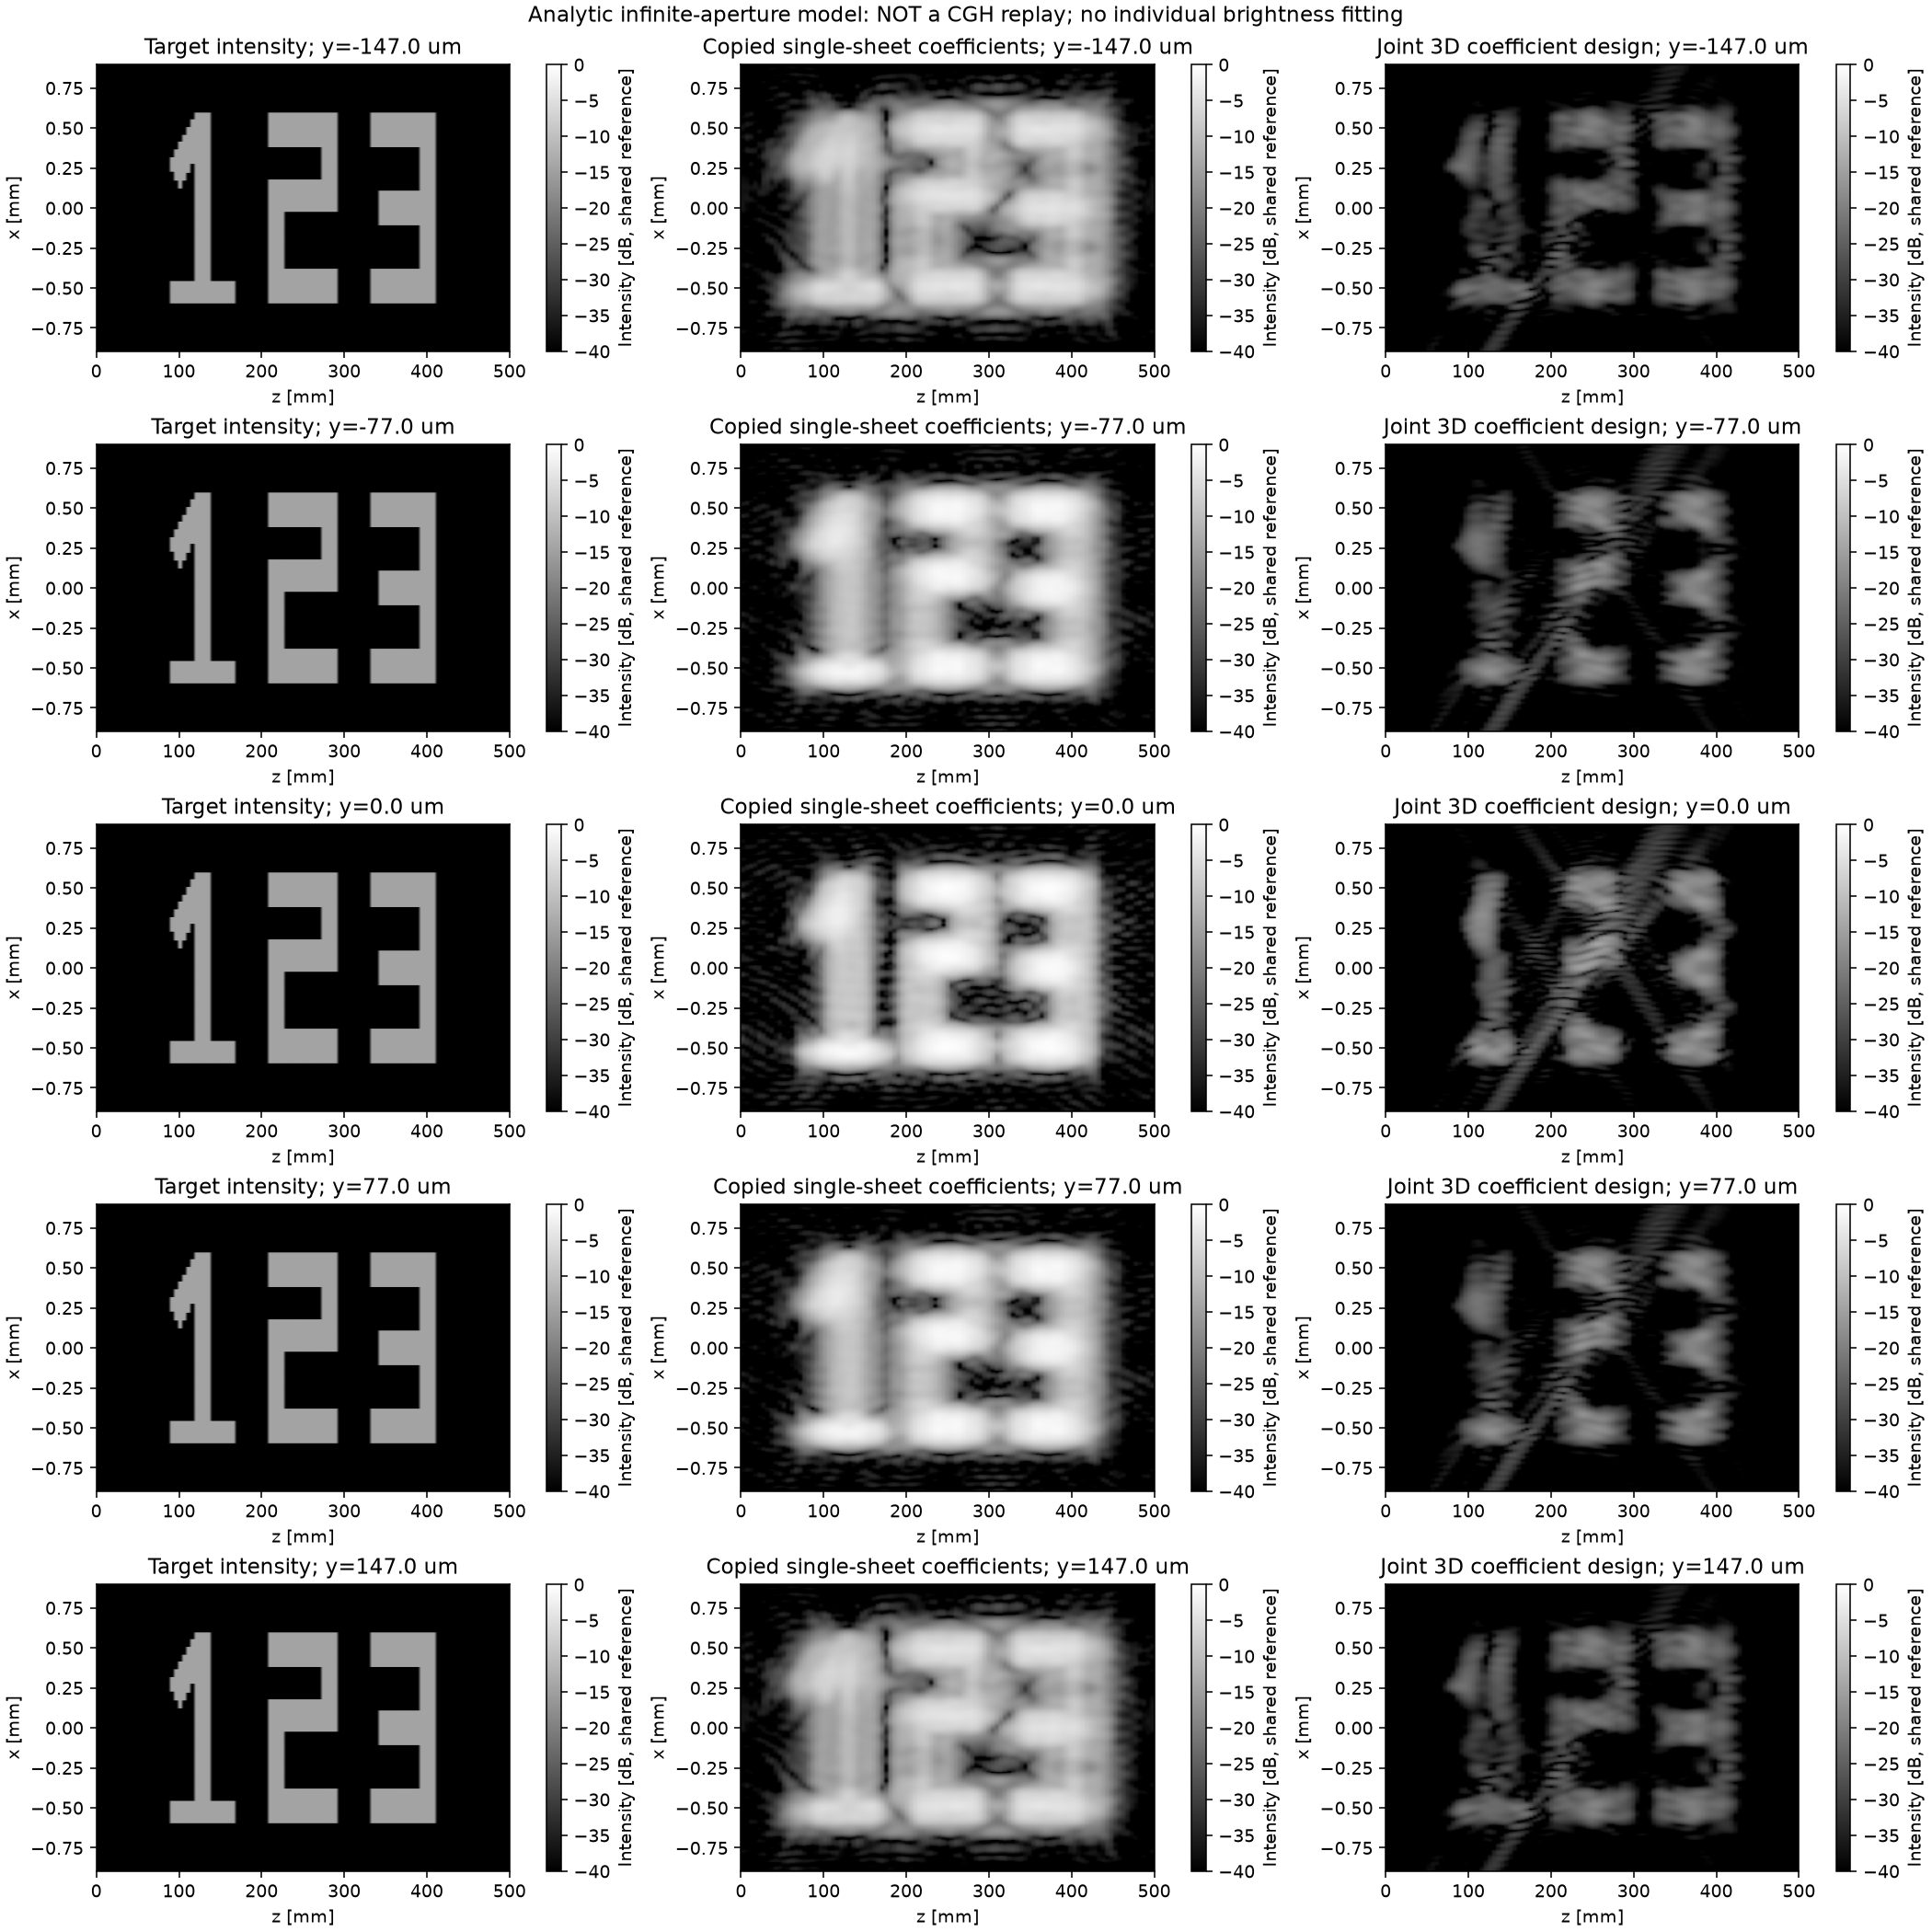

design_diagnostics.png


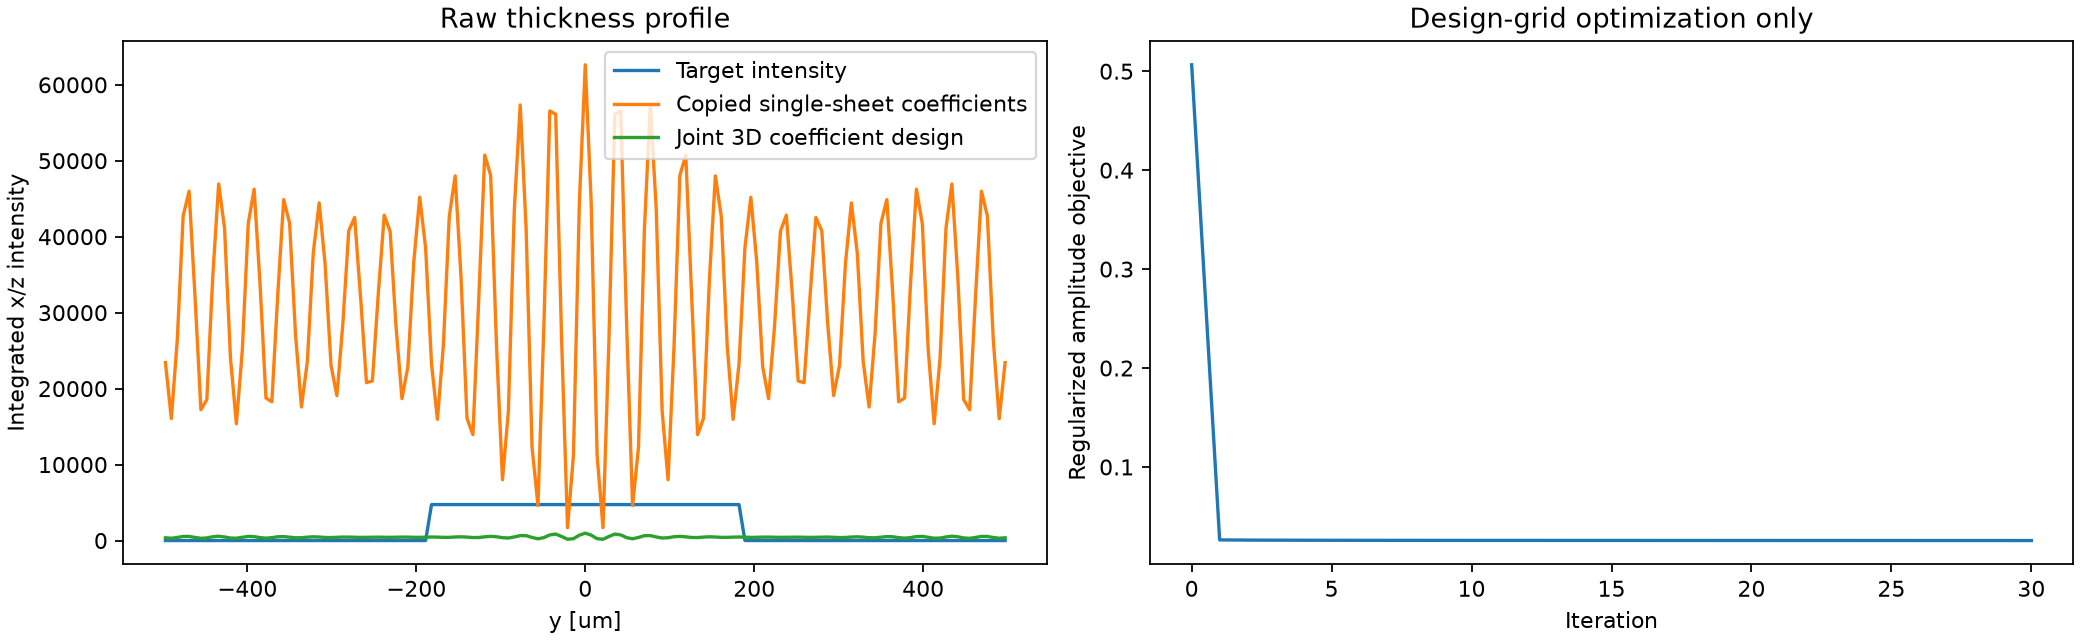

In [4]:
for name in ('analytic_sheets.png', 'analytic_sheets_db.png', 'design_diagnostics.png'):
    print(name)
    display(Image(filename=str(OUTPUT_DIR / name), width=1500))


## 次の段階

まず上の画像と数値を確認します。直接法の形状や背景光が改善しない場合は、ここでkrの帯域・配置・設計条件を検討します。画像の外側を切り取って改善したように見せることはしません。

解析モデルで納得できる結果が得られたら、次のセルの `RUN_FULL_CGH = True` を明示して、有限開口・CGH・伝搬・圧縮の比較へ進めます。直接法の2048²・8815項の新規生成があるため、この段階は重い処理です。以前の再生像は使い回しません。


In [5]:
RUN_FULL_CGH = False  # まず解析的な直接法の結果を確認する。
if RUN_FULL_CGH:
    FULL_OUTPUT_DIR = Path(f'lsh_multisheet_outputs_joint_rank{stack.rank}_{datetime.now():%Y%m%d_%H%M%S_%f}')
    full_summary = multisheet.run_multisheet(
        REFERENCE_DIR, FULL_OUTPUT_DIR, stack,
        coefficient_path=OUTPUT_DIR / 'coefficient_design.npz',
    )
    print('CGH・伝搬・圧縮の結果:', FULL_OUTPUT_DIR.resolve())
else:
    print('有限CGH・圧縮の計算は未実行です。まず直接法の像を確認してください。')


有限CGH・圧縮の計算は未実行です。まず直接法の像を確認してください。
